# Chapter 23 | Complete worked solutions

*Vision–Language and Multimodal Models*

All eleven exercises are solved here. We trace shared vectors into scores, distinguish two retrieval metrics, and follow visual information into a language model. Small arrays make every numerical result inspectable. The last exercises specify evaluation protocols and include synthetic checks of their accounting. They are teaching examples, not results from a trained visual assistant.

The written PDF includes all explanations and three plots. The notebook PDF also includes the code and recorded outputs. Run cells in order on CPU inside `transformers-book`; no image dataset or model download is required.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch23_multimodal"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from examples.ch04_attention.attention import stable_softmax
from examples.ch23_multimodal.model import contrastive_logits, symmetric_contrastive_loss, bidirectional_recall_at_k, image_feature_bridge
print("NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.5.4 | Matplotlib 3.11.2


## 1. Normalize two modalities

The image rows $(3,0)$ and $(0,2)$ have lengths 3 and 2. The text rows $(1,1)$ and $(0,2)$ have lengths $\sqrt2$ and 2. Divide each row by its own length, not by a shared batch norm:

$$
I=\begin{bmatrix}1&0\\0&1\end{bmatrix},\qquad
T=\begin{bmatrix}1/\sqrt2&1/\sqrt2\\0&1\end{bmatrix}.
$$

Each image–text dot product is a cosine similarity because both rows are unit vectors. Image 1 selects the first coordinate of each text; image 2 selects the second. Multiply by scale 2 to obtain

$$
L=2IT^{\mathsf T}=\begin{bmatrix}\sqrt2&0\\\sqrt2&2\end{bmatrix}.
$$

The first image ranks text 1 above text 2 because $\sqrt2>0$. Both modalities have two features, but equal width alone would not make independently learned axes correspond. In a real dual encoder, paired training learns that correspondence.

In [2]:
images=np.array([[3.,0.],[0.,2.]])
texts=np.array([[1.,1.],[0.,2.]])
unit_images=images/np.linalg.norm(images,axis=1,keepdims=True)
unit_texts=texts/np.linalg.norm(texts,axis=1,keepdims=True)
logits=contrastive_logits(images,texts,2)
np.testing.assert_allclose(logits,[[np.sqrt(2),0],[np.sqrt(2),2]])
print("Unit image rows:\n",unit_images)
print("Unit text rows:\n",unit_texts.round(6))
print("Logits:\n",logits.round(6))
print("Image 1 text ranking (1-based):",(np.argsort(-logits[0])+1).tolist())

Unit image rows:
 [[1. 0.]
 [0. 1.]]
Unit text rows:
 [[0.707107 0.707107]
 [0.       1.      ]]
Logits:
 [[1.414214 0.      ]
 [1.414214 2.      ]]
Image 1 text ranking (1-based): [1, 2]


## 2. Read a row and a column

The supplied training pairs lie on the diagonal of the logit matrix:

$$
L=\begin{bmatrix}1&0\\2&3\end{bmatrix}.
$$

Its two axes define two different competitions. Image 1 compares texts by reading row 1, $(1,0)$. Text 1 compares images by reading column 1, $(1,2)$. Their paired probabilities are

$$
p(T_1\mid I_1,\text{candidates})=\frac{e^1}{e^1+e^0}\approx0.731059,
\qquad
p(I_1\mid T_1,\text{candidates})=\frac{e^1}{e^1+e^2}\approx0.268941.
$$

The same numerator faces different competitors. The paired logit wins the row competition but loses the column competition. These are conditional distributions over supplied candidates, not vocabulary distributions or guaranteed probabilities of factual correctness. In the plot, each middle-panel row sums to one and each right-panel column sums to one.

Paired I1/T1: row 0.731059 column 0.268941


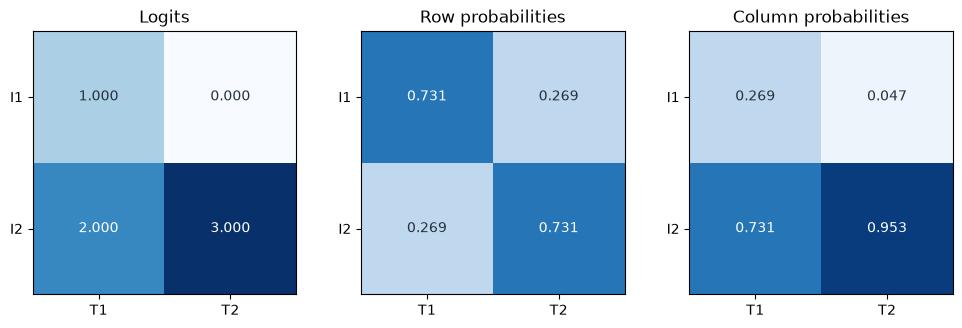

In [3]:
scores=np.array([[1.,0.],[2.,3.]])
row_prob=stable_softmax(scores)
column_prob=stable_softmax(scores.T).T
np.testing.assert_allclose(row_prob.sum(1),1)
np.testing.assert_allclose(column_prob.sum(0),1)
np.testing.assert_allclose(row_prob[0,0],1/(1+np.exp(-1)))
np.testing.assert_allclose(column_prob[0,0],1/(1+np.exp(1)))
print("Paired I1/T1: row",round(row_prob[0,0],6),"column",round(column_prob[0,0],6))
fig,axes=plt.subplots(1,3,figsize=(10,3.2))
for ax,values,title in zip(axes,[scores,row_prob,column_prob],
        ["Logits", "Row probabilities", "Column probabilities"]):
    maximum=3 if title=="Logits" else 1
    ax.imshow(values,cmap="Blues",vmin=0,vmax=maximum)
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["T1","T2"],
           yticklabels=["I1","I2"],title=title)
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f"{values[i,j]:.3f}",ha="center",va="center",
                    color="white" if values[i,j]>.55*maximum else "#26323D")
fig.tight_layout()
plt.show()

## 3. Count more than one valid caption

The relevant set is $\{C1,C3\}$, but the ranking is C2, C3, C4, C1. Its denominator stays two as we reveal more results. A hit records only whether any relevant caption has appeared.

| Cutoff | Retrieved captions | Relevant found | Recall | Hit |
| --- | --- | --- | --- | --- |
| 1 | C2 | 0 | $0/2=0$ | 0 |
| 2 | C2, C3 | 1 | $1/2$ | 1 |
| 4 | C2, C3, C4, C1 | 2 | $2/2=1$ | 1 |

At rank two the system has a hit but has found only half of the valid captions. At rank three, C4 adds neither a new hit nor a relevant caption. The graph shows the fraction of the relevant set found and the any-hit indicator separately.

Recall at 1, 2, 4: [0.0, 0.5, 1.0]
Hits at 1, 2, 4: [0, 1, 1]


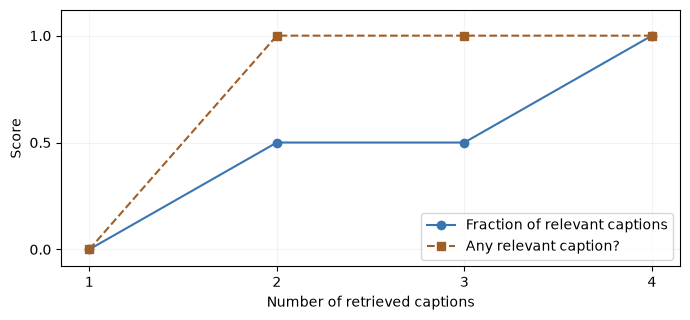

In [4]:
ranking=["C2","C3","C4","C1"];relevant={"C1","C3"}
counts=np.cumsum([name in relevant for name in ranking])
recall=counts/len(relevant);hits=(counts>0).astype(int)
np.testing.assert_allclose(recall,[0,.5,.5,1])
np.testing.assert_array_equal(hits,[0,1,1,1])
print("Recall at 1, 2, 4:",recall[[0,1,3]].tolist())
print("Hits at 1, 2, 4:",hits[[0,1,3]].tolist())
fig,ax=plt.subplots(figsize=(7,3.3))
ax.plot(range(1,5),recall,"o-",label="Fraction of relevant captions",color="#3976AF")
ax.plot(range(1,5),hits,"s--",label="Any relevant caption?",color="#A25E27")
ax.set(xticks=range(1,5),yticks=[0,.5,1],ylim=(-.08,1.12),
       xlabel="Number of retrieved captions",ylabel="Score")
ax.legend(loc="lower right");ax.grid(alpha=.15);fig.tight_layout();plt.show()

## 4. Mix values before projection

Both attention scores are zero, so their exponentials are $(1,1)$ and their normalized weights are $(1/2,1/2)$. Average the two value rows:

$$
C=\tfrac12(2,1)+\tfrac12(0,3)=(1,2).
$$

The projection has two input features and three output features. Multiplying the context row by it gives

$$
Z=(1,2)\begin{bmatrix}1&0&2\\0&1&-1\end{bmatrix}
=(1,0,2)+2(0,1,-1)=(1,2,0).
$$

The output is a two-dimensional array with shape $[1,3]$: one row because there was one query and three features because the projection has three columns. A projection changes feature width without making additional query rows. Its coordinates are continuous features; they do not have to sum to one.

In [5]:
weights=stable_softmax(np.array([[0.,0.]]))
values=np.array([[2.,1.],[0.,3.]])
projection=np.array([[1.,0.,2.],[0.,1.,-1.]])
context=weights@values;projected=context@projection
np.testing.assert_allclose(weights,[[.5,.5]])
np.testing.assert_allclose(context,[[1,2]])
np.testing.assert_allclose(projected,[[1,2,0]])
assert projected.shape==(1,3)
print("Weights",weights,"Context",context)
print("Projected row",projected,"Shape",projected.shape)

Weights [[0.5 0.5]] Context [[1. 2.]]
Projected row [[1. 2. 0.]] Shape (1, 3)


## 5. Check row normalization

Start with the image and text vectors from Exercise 1. Stretch the first
image vector from $(3,0)$ to $(15,0)$. Both point in the same direction.
Dividing each by its length gives $(1,0)$ in either case.

For a nonzero row $v$ and a positive multiplier $c$, the Euclidean
length scales by $c$. This makes the unit row invariant, meaning it
stays the same after the stretch.

$$
\frac{cv}{\lVert cv\rVert_2}
=\frac{cv}{c\lVert v\rVert_2}
=\frac{v}{\lVert v\rVert_2}.
$$

The normalized image rows are $(1,0)$ and $(0,1)$. The normalized text
rows are $(1/\sqrt{2},1/\sqrt{2})$ and $(0,1)$. Taking every image–text
dot product and multiplying by 2 gives the logits, or scores before
softmax. At scale 4, the same dot products get twice the score.

$$
L_2=\begin{bmatrix}\sqrt{2}&0 \\ \sqrt{2}&2\end{bmatrix},
\qquad
L_4=\begin{bmatrix}2\sqrt{2}&0 \\ 2\sqrt{2}&4\end{bmatrix}.
$$

The first image ranks text 1 first, and the second image ranks text 2
first. Multiplying every score by the same positive number preserves
inequalities and ties. This applies to rankings along rows and columns.

In [6]:
from examples.ch23_multimodal.model import contrastive_logits

images = np.array([[3.0, 0.0], [0.0, 2.0]])
texts = np.array([[1.0, 1.0], [0.0, 2.0]])
stretched_images = images.copy()
stretched_images[0] *= 5

original = contrastive_logits(images, texts, scale=2)
stretched = contrastive_logits(stretched_images, texts, scale=2)
rescaled = contrastive_logits(stretched_images, texts, scale=4)

root_two = np.sqrt(2)
expected_at_two = np.array([[root_two, 0], [root_two, 2]])
expected_text_order = [[1, 2], [2, 1]]
cases = [
    ("Original images, scale 2", original, expected_at_two),
    ("Stretched first image, scale 2", stretched, expected_at_two),
    ("Stretched first image, scale 4", rescaled, 2 * expected_at_two),
]
for label, scores, expected in cases:
    np.testing.assert_allclose(scores, expected)
    text_order = np.argsort(-scores, axis=1, kind="stable") + 1
    np.testing.assert_array_equal(text_order, expected_text_order)
    print(label)
    print(np.array2string(scores, precision=6, floatmode="fixed"))
    print(f"Text order by image (1-based) {text_order.tolist()}")
    paired_probability = 1 / (1 + np.exp(scores[0, 1] - scores[0, 0]))
    print(f"P(text 1 | image 1) = {paired_probability:.6f}")

Original images, scale 2
[[1.414214 0.000000]
 [1.414214 2.000000]]
Text order by image (1-based) [[1, 2], [2, 1]]
P(text 1 | image 1) = 0.804430
Stretched first image, scale 2
[[1.414214 0.000000]
 [1.414214 2.000000]]
Text order by image (1-based) [[1, 2], [2, 1]]
P(text 1 | image 1) = 0.804430
Stretched first image, scale 4
[[2.828427 0.000000]
 [2.828427 4.000000]]
Text order by image (1-based) [[1, 2], [2, 1]]
P(text 1 | image 1) = 0.944193


Softmax turns a row of scores into probabilities by exponentiating
and dividing by the sum of the exponentials. The first row has two
candidates, so the probability of text 1 simplifies to
$1/(1+e^{L_{12}-L_{11}})$, using one-based indices. Doubling the scale
doubles the gap between the two scores. This raises the probability
from about $0.804$ to $0.944$ while text 1 stays in first place.

The candidate list also affects the probability. At scale 2, duplicate text 2. The first image now sees logits $(\sqrt2,0,0)$. The probability of text 1 becomes

$$
\frac{e^{\sqrt2}}{e^{\sqrt2}+2}\approx0.672842,
$$

instead of about 0.804430. It still has the highest individual score. The denominator grew because there are now three entries. Neither this change nor sharpening the distribution establishes better factual accuracy. The duplicated description is counted twice in this candidate-entry calculation; a class-level evaluation would need a stated rule for combining multiple prompts.

In [7]:
two=contrastive_logits(images,texts,2)
three=contrastive_logits(images,np.vstack([texts,texts[1]]),2)
p_two=stable_softmax(two)[0,0];p_three=stable_softmax(three)[0,0]
np.testing.assert_allclose(three[0],[np.sqrt(2),0,0])
np.testing.assert_allclose(p_three,np.exp(np.sqrt(2))/(np.exp(np.sqrt(2))+2))
assert p_three<p_two and np.argmax(three[0])==0
print("Two candidates:",round(p_two,6))
print("With duplicated text 2:",round(p_three,6))

Two candidates: 0.80443
With duplicated text 2: 0.672842


## 6. Transpose a contrastive batch

Use the scores from Exercise 2. Each row starts as an image query
against two text candidates. Each column is a text query against two
image candidates. The two supplied pairs occupy the diagonal.

$$
L=\begin{bmatrix}1&0\\2&3\end{bmatrix},
\qquad
L^{\mathsf T}=\begin{bmatrix}1&2\\0&3\end{bmatrix}.
$$

For each query, the loss is the negative natural log of the softmax
probability of its paired candidate. With two candidates, let $d$ be
the paired score minus the other score. The paired probability is
$1/(1+e^{-d})$, so the loss is $\ln(1+e^{-d})$. Average the two query
losses for each direction.

Across rows, the gaps are $1-0=1$ and $3-2=1$. The image-to-text
  loss is $\ln(1+e^{-1})\approx0.313262$.
Down columns, the gaps are $1-2=-1$ and $3-0=3$. The text-to-image
  loss is $[\ln(1+e)+\ln(1+e^{-3})]/2\approx0.680925$.

The mean of the two directional losses is about $0.497093$. The code
calls the chapter function on both matrices and compares its return
values with this arithmetic.

In [8]:
from math import exp, log1p

from examples.ch23_multimodal.model import symmetric_contrastive_loss

logits = np.array([[1.0, 0.0], [2.0, 3.0]])
row_loss, column_loss, mean_loss = symmetric_contrastive_loss(logits)
transpose_row, transpose_column, transpose_mean = (
    symmetric_contrastive_loss(logits.T)
)

expected_row = log1p(exp(-1))
expected_column = (log1p(exp(1)) + log1p(exp(-3))) / 2
expected_mean = (expected_row + expected_column) / 2
np.testing.assert_allclose(
    (row_loss, column_loss, mean_loss),
    (expected_row, expected_column, expected_mean),
)
np.testing.assert_allclose(
    (transpose_row, transpose_column, transpose_mean),
    (expected_column, expected_row, expected_mean),
)

In [9]:
loss_cases = [
    ("L", row_loss, column_loss, mean_loss),
    ("L.T", transpose_row, transpose_column, transpose_mean),
]
print(f"{'Input':<6} {'First (rows)':>13} "
      f"{'Second (cols)':>13} {'Mean':>10}")
for label, first, second, mean in loss_cases:
    print(f"{label:<6} {first:>13.6f} {second:>13.6f} {mean:>10.6f}")

Input   First (rows) Second (cols)       Mean
L           0.313262      0.680925   0.497093
L.T         0.680925      0.313262   0.497093


The transpose turns each original column into a row and each
original row into a column. It keeps each paired score at the same
diagonal position. The first returned loss therefore compares the
original images for each text after transposition. The second loss
compares the original texts for each image. Exchanging the two losses
leaves their arithmetic mean unchanged.

## 7. Build a rectangular retrieval task

There are two images, I1 and I2, and three captions, C1 through C3.
The score and relevance matrices both have shape $2\times3$. A score
determines where a candidate ranks. The Boolean relevance entry
says whether that candidate counts as a correct result. Here C1
and C2 are valid for I1, and C3 is valid for I2.

To retrieve captions, rank each image's row from highest to lowest
score. To retrieve images, rank each caption's column. The same
relevance entries apply in both directions. For each query,
recall at $k$ divides the number of relevant items in the first
$k$ results by the number of relevant items for that query.

| Query | Candidates in score order | Relevant candidates | Recall at 1 | Recall at 2 |
| --- | --- | --- | --- | --- |
| I1 | C1, C2, C3 | C1, C2 | $1/2$ | $2/2$ |
| I2 | C3, C2, C1 | C3 | $1/1$ | $1/1$ |
| C1 | I1, I2 | I1 | $1/1$ | $1/1$ |
| C2 | I2, I1 | I1 | $0/1$ | $1/1$ |
| C3 | I2, I1 | I2 | $1/1$ | $1/1$ |

For I1 at rank one, C1 accounts for only half of the two valid
captions. For C2, the scores are $1$ for I1 and $2$ for I2, so the
only relevant image appears at rank two. Each mean gives equal
weight to every query with defined recall. At $k=1$ the means are
$(1/2+1)/2=3/4$ for image-to-text and $(1+0+1)/3=2/3$ for
text-to-image. At $k=2$ every query has retrieved all of its
relevant items, so both means are $1$.

In [10]:
from examples.ch23_multimodal.model import bidirectional_recall_at_k

scores = np.array([[2, 1, 0], [0, 2, 3]])
relevance = np.array([[1, 1, 0], [0, 0, 1]], dtype=bool)

# Expected per-query recall and mean from the hand calculation.
expected_recall = {
    1: {
        "image_to_text": ([1 / 2, 1], 3 / 4),
        "text_to_image": ([1, 0, 1], 2 / 3),
    },
    2: {
        "image_to_text": ([1, 1], 1),
        "text_to_image": ([1, 1, 1], 1),
    },
}

print(f"{'k':>1}  {'Direction':<13} {'per_query':<17} {'mean':>8}")
for k, expected_directions in expected_recall.items():
    recall = bidirectional_recall_at_k(scores, relevance, k)
    for direction, expected in expected_directions.items():
        result = recall[direction]
        per_query, mean = result["per_query"], result["mean"]
        expected_per_query, expected_mean = expected
        np.testing.assert_allclose(per_query, expected_per_query)
        np.testing.assert_allclose(mean, expected_mean)
        assert result["defined_queries"] == len(expected_per_query)

        label = direction.replace("_", "-")
        print(f"{k:>1}  {label:<13} {str(per_query):<17} "
              f"{mean:>8.6f}")

k  Direction     per_query             mean
1  image-to-text [0.5, 1.0]        0.750000
1  text-to-image [1.0, 0.0, 1.0]   0.666667
2  image-to-text [1.0, 1.0]        1.000000
2  text-to-image [1.0, 1.0, 1.0]   1.000000


C2 contributes a defined zero to the text-to-image mean at $k=1$
because it has a relevant image outside the top result. Every
caption has a relevant image in this exercise. If we removed the
C2 relevance mark for I1, its column would contain all `False`.
The denominator would be zero, so the function would return `None`
for C2 and average the two remaining caption queries.

The given scores have no tie within any query's ranking. When two
candidates for the same query have equal scores, the function
preserves their order in the input. For example, if both images
scored $1$ for C2 and the original relevance labels were used,
I1 would come first and C2 would have recall $1$ at rank one.

## 8. Change what a query reads (optional)

Think of the two key and value rows as two image regions. The
query scores each region by comparing with its key. The attention
weights then determine how much of each region's value enters the
context row. We keep the same keys, values, and projection for
both runs.

The query $(0,\sqrt{2})$ has a dot product of $0$ with the first
key and $\sqrt{2}\ln 2$ with the second. Dividing by
$\sqrt{d_k}=\sqrt{2}$, where $d_k$ is the key width, gives
$(0,\ln 2)$. Softmax exponentiates the two scores and divides
each exponential by their sum. The exponentials $(1,2)$ become
weights $(1/3,2/3)$. The second value gets twice the weight of the
first. The weighted sum is
$$
\tfrac13(3,0)+\tfrac23(0,3)=(1,2).
$$

With the negated query $(0,-\sqrt{2})$, the scaled scores are
$(0,-\ln 2)$. The exponentials $(1,1/2)$ now give weights
$(2/3,1/3)$, so the first value gets twice the weight of the
second. The new context is
$$
\tfrac23(3,0)+\tfrac13(0,3)=(2,1).
$$

The projection sends a context row $(a,b)$ to $(a,b,a-b)$.
Multiply $a$ by the first projection row and $b$ by the second,
then add them. The two projected rows are therefore $(1,2,-1)$
and $(2,1,1)$. Each run starts with one query row of width two.
Its two weights produce one context row of width two. Multiplying
by the $2\times3$ projection gives one row of width three.

In [11]:
from examples.ch23_multimodal.model import image_feature_bridge

query = np.array([[0, np.sqrt(2)]])
keys = np.array([[0, 0], [0, np.log(2)]])
values = np.array([[3, 0], [0, 3]])
projection = np.array([[1, 0, 1], [0, 1, -1]])

# The hand calculation gives one row for each expected array.
bridge_cases = [
    ("Original", query, np.log(2), [[1 / 3, 2 / 3]], [[1, 2]],
     [[1, 2, -1]]),
    ("Negated", -query, -np.log(2), [[2 / 3, 1 / 3]], [[2, 1]],
     [[2, 1, 1]]),
]

assert query.shape == (1, 2)
assert keys.shape == values.shape == (2, 2)
assert projection.shape == (2, 3)
for label, active_query, log_score, want_weights, want_ctx, want in (
    bridge_cases
):
    context, weights, projected = image_feature_bridge(
        active_query, keys, values, projection
    )
    scaled_scores = active_query @ keys.T / np.sqrt(keys.shape[1])
    np.testing.assert_allclose(scaled_scores, [[0, log_score]])
    np.testing.assert_allclose(weights, want_weights)
    np.testing.assert_allclose(context, want_ctx)
    np.testing.assert_allclose(projected, want)

    print(f"{label} query")
    print(f"  Scaled scores  {np.round(scaled_scores, 6)}")
    print(f"  Weights        {np.round(weights, 6)}")
    print(f"  Context        {context}")
    print(f"  Projected row  {projected}")

print(f"Shapes  weights {weights.shape}, context {context.shape}, "
      f"projection output {projected.shape}")

Original query
  Scaled scores  [[0.       0.693147]]
  Weights        [[0.333333 0.666667]]
  Context        [[1. 2.]]
  Projected row  [[ 1.  2. -1.]]
Negated query
  Scaled scores  [[-0.       -0.693147]]
  Weights        [[0.666667 0.333333]]
  Context        [[2. 1.]]
  Projected row  [[2. 1. 1.]]
Shapes  weights (1, 2), context (1, 2), projection output (1, 3)


## 9. Keep related pairs together (optional)

Use the scene as the splitting unit. Attach every caption to its photo ID and each photo to a scene ID. Group near-duplicates before assigning splits; copies, crops, adjacent frames and nearly identical views must not straddle the boundary. If duplicate clusters connect two proposed scene groups, merge those groups. Choose retrieval settings on validation scenes, then freeze them before evaluating test scenes.

Keep all five captions for each held-out photo. Build a relevance matrix before scoring. The five parent captions are positives; other captions may also be valid if the annotation policy explicitly judges them relevant. Sharing a scene ID alone does not establish relevance: a sentence about a red bus may not describe the blue bus in another view. Reverse the same relevance links for text-to-image retrieval.

Report mean per-query recall separately for each direction at fixed cutoffs, with gallery sizes, tie rules, defined-query counts and excluded-query counts. If two of a photo's five valid captions appear in the first three results, its recall is $2/5$ and its hit indicator is 1. A text with one relevant photo at rank two has recall zero at one and one at three. Report any-hit scores under a separate name. Resample scenes, rather than individual correlated captions, when estimating uncertainty.

The small audit below constructs six scene groups, two photos per scene and five captions per photo. Its training, validation and test counts are respectively (3 scenes, 6 photos, 30 captions), (2, 4, 20) and (1, 2, 10). These counts demonstrate grouping; they are not a recommended dataset size or measured retrieval performance.

In [12]:
scene_split={f"S{i}":("train" if i<3 else "validation" if i<5 else "test") for i in range(6)}
records=[(scene,f"{scene}-P{photo}",f"{scene}-P{photo}-C{caption}",split)
         for scene,split in scene_split.items() for photo in range(2) for caption in range(5)]
for field in (0,1,2):
    for identifier in {record[field] for record in records}:
        assert len({record[3] for record in records if record[field]==identifier})==1
for split in ("train","validation","test"):
    rows=[record for record in records if record[3]==split]
    counts=[len({record[field] for record in rows}) for field in (0,1,2)]
    print(split,"scenes, photos, captions:",counts)
assert len(records)==60
print("Example recall with 2 of 5 valid captions:",2/5,"; hit:",1)

train scenes, photos, captions: [3, 6, 30]
validation scenes, photos, captions: [2, 4, 20]
test scenes, photos, captions: [1, 2, 10]
Example recall with 2 of 5 valid captions: 0.4 ; hit: 1


## 10. Test a spatial relation (optional)

Ask: *Is the bus to the left or to the right of the shelter in the picture?* Use the viewer's frame of reference. Keep the shelter, road, colors and bus shape fixed while moving the bus horizontally. The figure below gives expected answers left and right. It defines a test pair, not model predictions. A real model should receive only the scene pixels, without the expected-answer labels or panel titles.

Run the two images independently with the same question and fixed decoding settings. Balance labels and randomize presentation order across many scenes. Keep pairs together in the data split. Predefine accepted wording, including phrases such as “to its left.” Report image accuracy and the fraction of pairs for which both answers are correct. Merely changing the answer earns no credit unless both answers match their images.

For the four supplied pairs, the expected answer sequence is (left, right) each time:

| Pair | Predictions | Correct images | Both correct? | Answers differ? |
| --- | --- | --- | --- | --- |
| 1 | left, right | 2 | 1 | 1 |
| 2 | left, left | 1 | 0 | 0 |
| 3 | right, left | 0 | 0 | 1 |
| 4 | right, right | 1 | 0 | 0 |

Image accuracy is $4/8=1/2$, both-correct pair accuracy is $1/4$, and the fraction whose answers differ is $2/4=1/2$. Pair 3 changes its answer in the wrong direction.

A deterministic question-only model receives identical text twice. Always answering left yields 50% image accuracy and 0% pair accuracy. Independent uniform left/right guesses have expected image accuracy 50% and pair accuracy 25%; these are expectations, not guaranteed values in four pairs. An unchanged visual-model answer shows failure on that pair, but does not identify the internal cause or prove the model never reads images.

Image accuracy 0.5 Pair accuracy 0.25 Changed answers 0.5


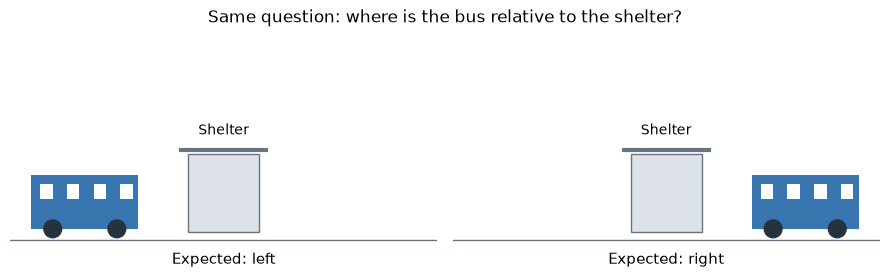

In [13]:
expected=np.array(["left","right"])
predicted=np.array([["left","right"],["left","left"],["right","left"],["right","right"]])
correct=predicted==expected
image_accuracy=correct.mean();pair_accuracy=correct.all(1).mean()
changed=(predicted[:,0]!=predicted[:,1]).mean()
np.testing.assert_allclose([image_accuracy,pair_accuracy,changed],[.5,.25,.5])
print("Image accuracy",image_accuracy,"Pair accuracy",pair_accuracy,"Changed answers",changed)
fig,axes=plt.subplots(1,2,figsize=(9,3.2))
for ax,bus_x,label in zip(axes,[.6,8.4],["left","right"]):
    ax.set(xlim=(0,12),ylim=(0,5),aspect="equal")
    ax.axis("off");ax.set_facecolor("#F4F7FA")
    ax.plot([0,12],[.8,.8],color="#687580",lw=1)
    ax.add_patch(Rectangle((5,1),2,2.2,facecolor="#DCE2E7",edgecolor="#687580"))
    ax.plot([4.8,7.2],[3.3,3.3],color="#687580",lw=3)
    ax.text(6,3.75,"Shelter",ha="center",fontsize=10)
    ax.add_patch(Rectangle((bus_x,1.1),3,1.5,facecolor="#3976AF"))
    for offset in (.25,1,1.75,2.5):
        ax.add_patch(Rectangle((bus_x+offset,1.95),.35,.4,facecolor="white"))
    for offset in (.6,2.4):
        ax.add_patch(Circle((bus_x+offset,1.1),.25,color="#26323D"))
    ax.text(6,.12,"Expected: "+label,ha="center",fontsize=11)
fig.suptitle("Same question: where is the bus relative to the shelter?",fontsize=12)
fig.tight_layout();plt.show()

## 11. Separate ambiguity from a wrong answer (optional)

Ask the fixed question *What color is the bus's body?* Annotate bus count, body colors and locations before scoring. Use clear images and define acceptable color synonyms in advance. Windows and lights do not determine the body's color.

| Image type | Acceptable response |
| --- | --- |
| One blue bus | Blue, or an equivalent supported body-color term |
| Blue bus on the left, red bus on the right | Which bus do you mean? Or correctly describe both buses |
| No bus | There is no bus visible |

Use two judgments: whether the response handles the question appropriately, and whether it makes an unsupported visual claim. A bare “blue” on the two-bus image fails to resolve the referent, although blue is present. “The right bus is blue” also assigns a color to the wrong object. “Do you mean the green bus?” sounds like clarification but introduces an absent green bus. A request for clarification on the single clear bus is unnecessary. Naming a bus color when no bus is visible assumes an object that is absent.

Report appropriate-response rates separately for single-bus, multiple-bus and no-bus cases. Within ambiguous cases, distinguish grounded clarification, explicit description of both possibilities and unjustified selection of one. Report unsupported-claim rates with raw counts independently; an output can fail both judgments. Fix prompt, image resolution and decoding settings across systems and review borderline color terms consistently.

The following six hand-labeled responses illustrate the bookkeeping. There are three appropriate responses and two unsupported claims. Of the three ambiguous-image responses, one is appropriate and one introduces an unsupported color. The code summarizes given human judgments; it does not automatically understand a generated answer.

In [14]:
responses=[
    ("single","Blue",True,False),
    ("multiple","Which bus do you mean?",True,False),
    ("multiple","Blue",False,False),
    ("multiple","Do you mean the green bus?",False,True),
    ("none","There is no bus visible",True,False),
    ("none","The bus is red",False,True),
]
assert sum(row[2] for row in responses)==3
assert sum(row[3] for row in responses)==2
for group in ("single","multiple","none"):
    rows=[row for row in responses if row[0]==group]
    appropriate=sum(row[2] for row in rows);unsupported=sum(row[3] for row in rows)
    print(group,"appropriate",f"{appropriate}/{len(rows)}",
          "unsupported",f"{unsupported}/{len(rows)}")
print("Overall appropriate: 3/6; unsupported: 2/6 (synthetic labels)")

single appropriate 1/1 unsupported 0/1
multiple appropriate 1/3 unsupported 1/3
none appropriate 1/2 unsupported 1/2
Overall appropriate: 3/6; unsupported: 2/6 (synthetic labels)
